# Image Processing
- Scanning Tunneling Microscope (STM) data
- Data on variation in altitude of the Earth's surface

## Altitude of Earth's surface

$ z = w(x,y) $ = surface = surface of earth (height of mountains)

or equivalently, $ z - w(x,y) = 0 $

The normal vector $\bold{v}$ to the surface is given by the gradient of $ z - w(x,y) $ thus:

$\bold{v} = \nabla{[z - w(x,y)]} = (\frac{\partial }{\partial x}, \frac{\partial }{\partial y}, \frac{\partial }{\partial z}) [z - w(x,y)] = (\frac{\partial w }{\partial x}, \frac{\partial w}{\partial y}, 1) $



$ I = - \frac{\cos{\phi}(\frac{\partial w}{\partial x}) + \sin{\phi}(\frac{\partial w}{\partial y})}{\sqrt{(\frac{\partial w}{\partial x})^{2} + (\frac{\partial w}{\partial y})^{2} + 1}} $ = Intensity of illumination

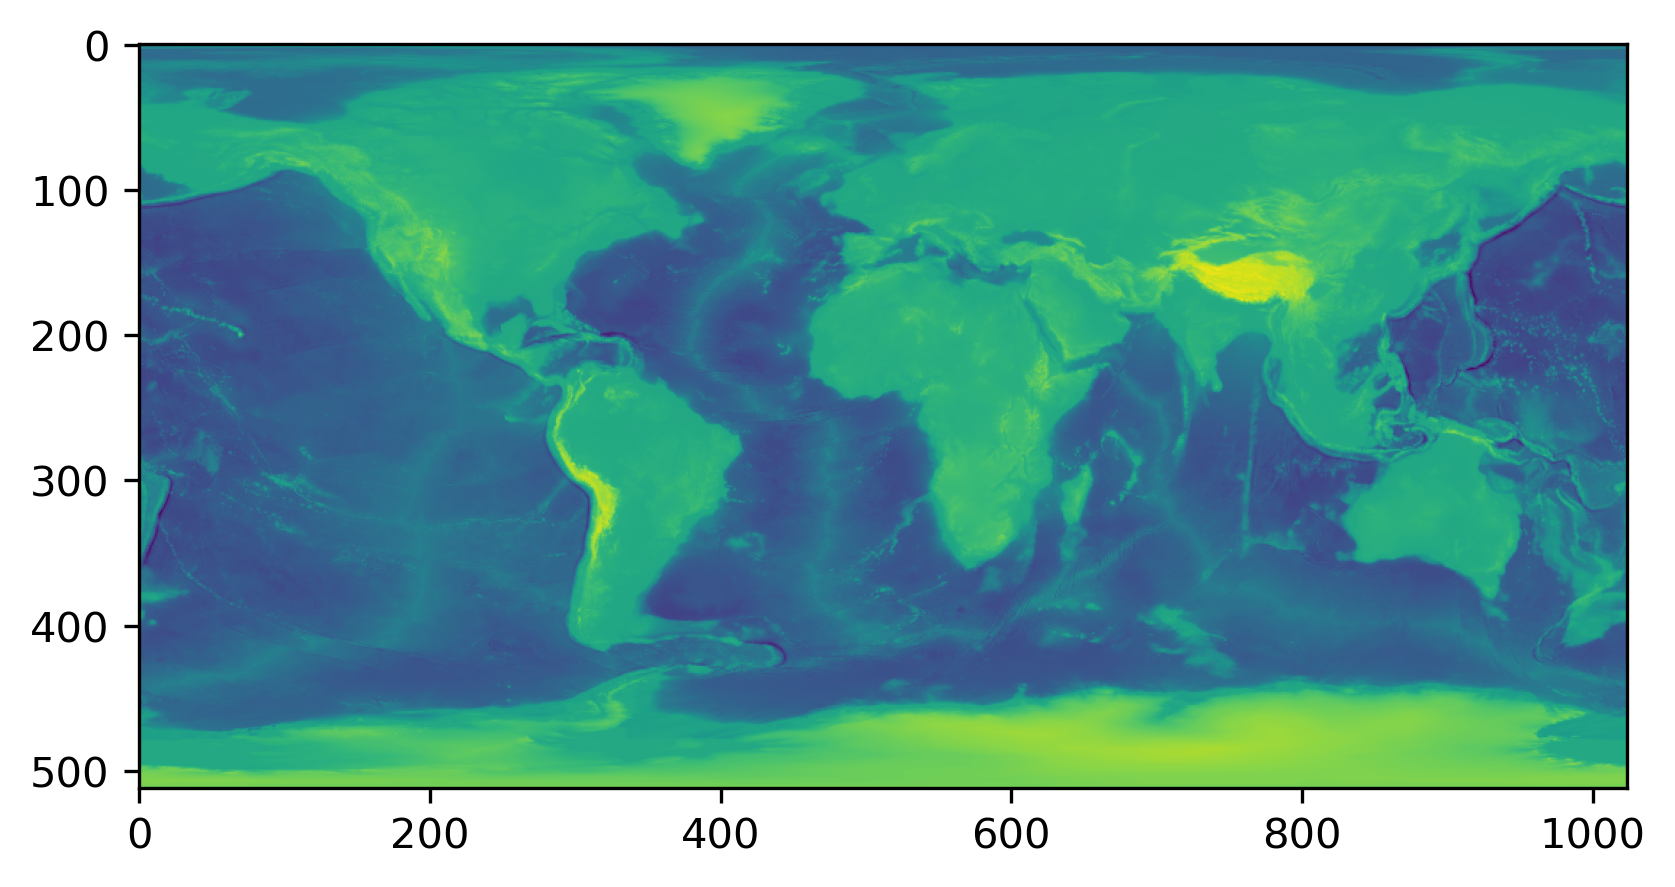

In [4]:
# exercise 5.23
import matplotlib.pyplot as plt
import numpy as np

import matplotlib
matplotlib.rcParams['figure.dpi']=300 # highres display

import pandas as pd

%matplotlib inline

altitude_data = pd.read_csv('altitude.txt', delim_whitespace=True, header=None,dtype=float)
 

plt.figure()

plt.imshow(altitude_data)

plt.show()

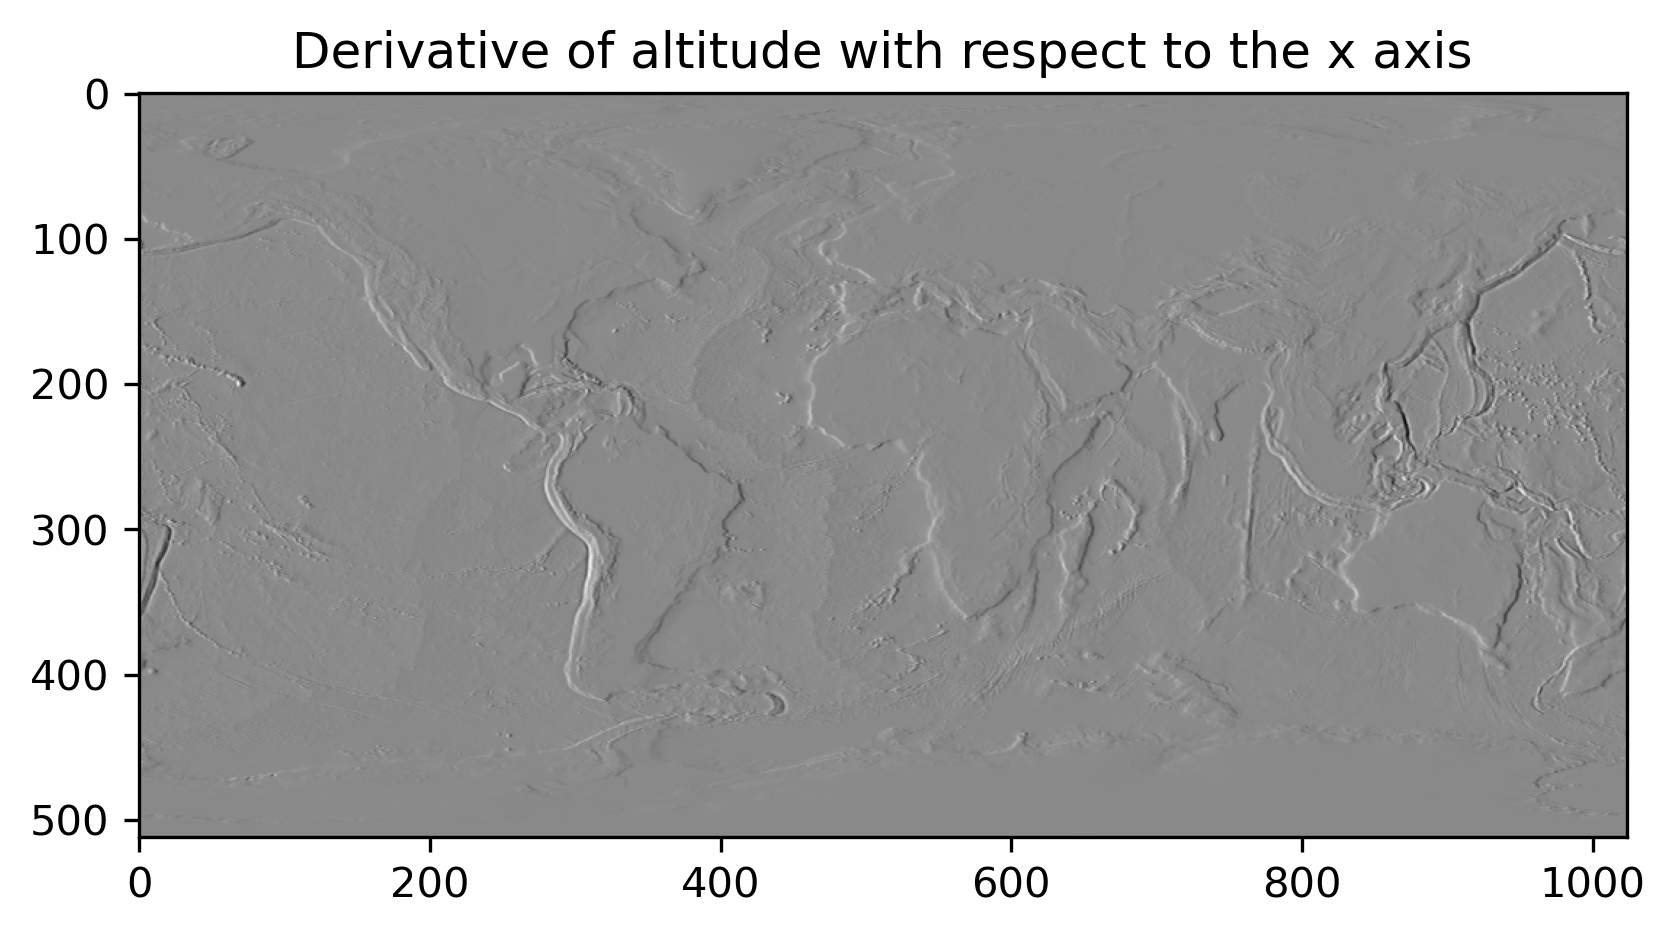

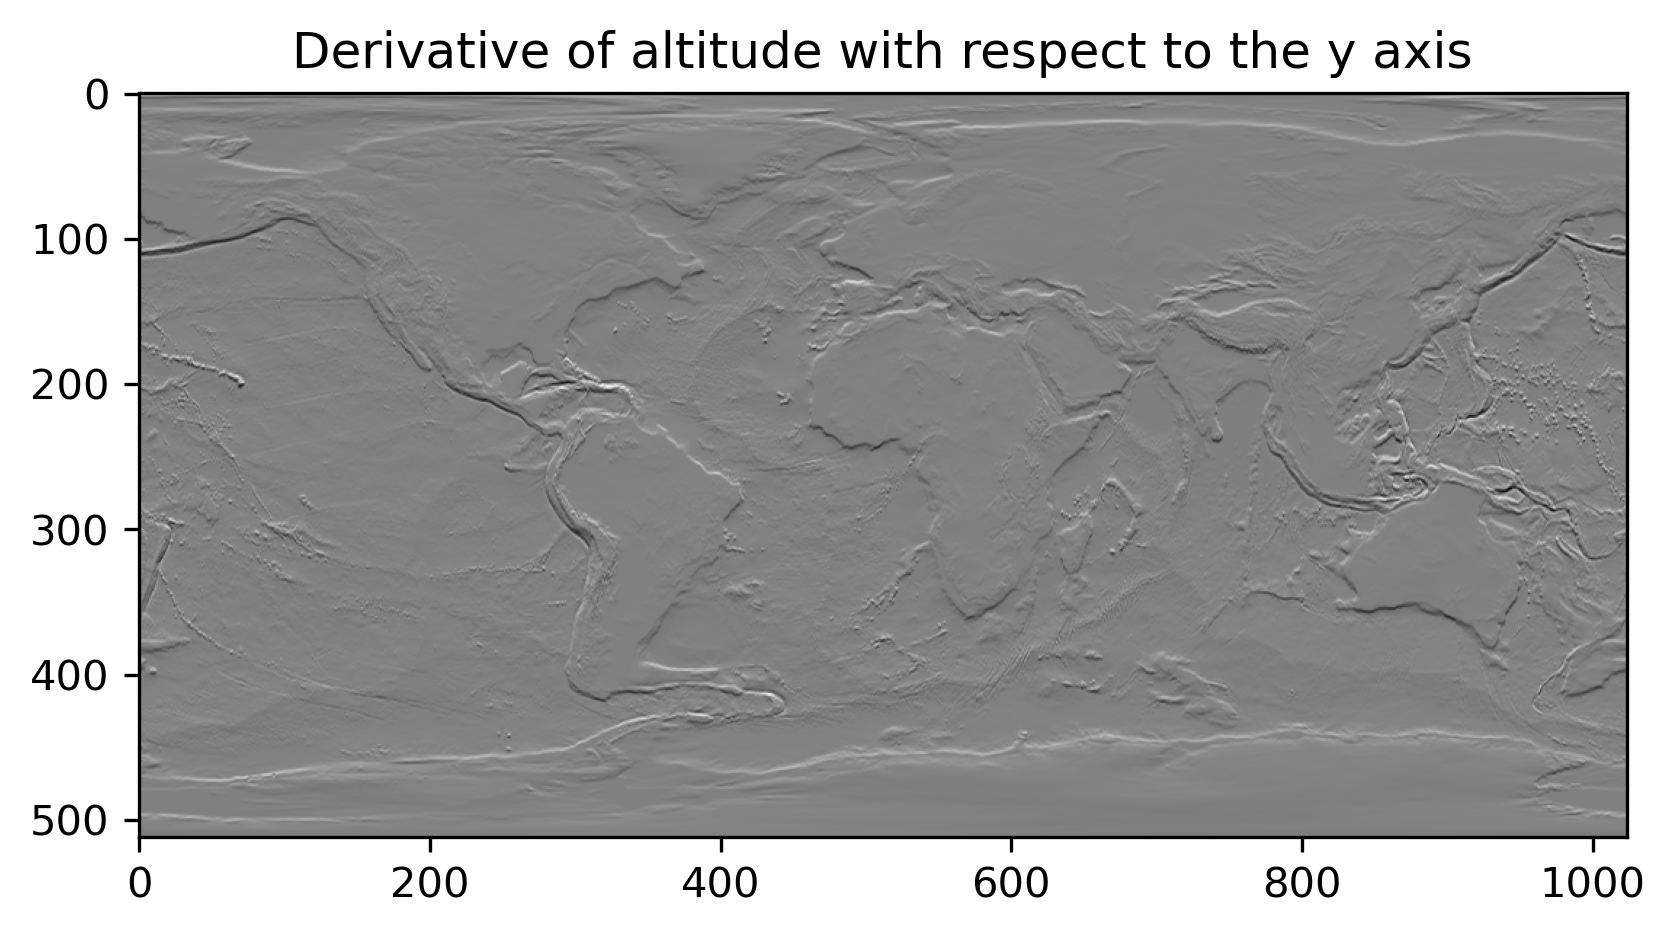

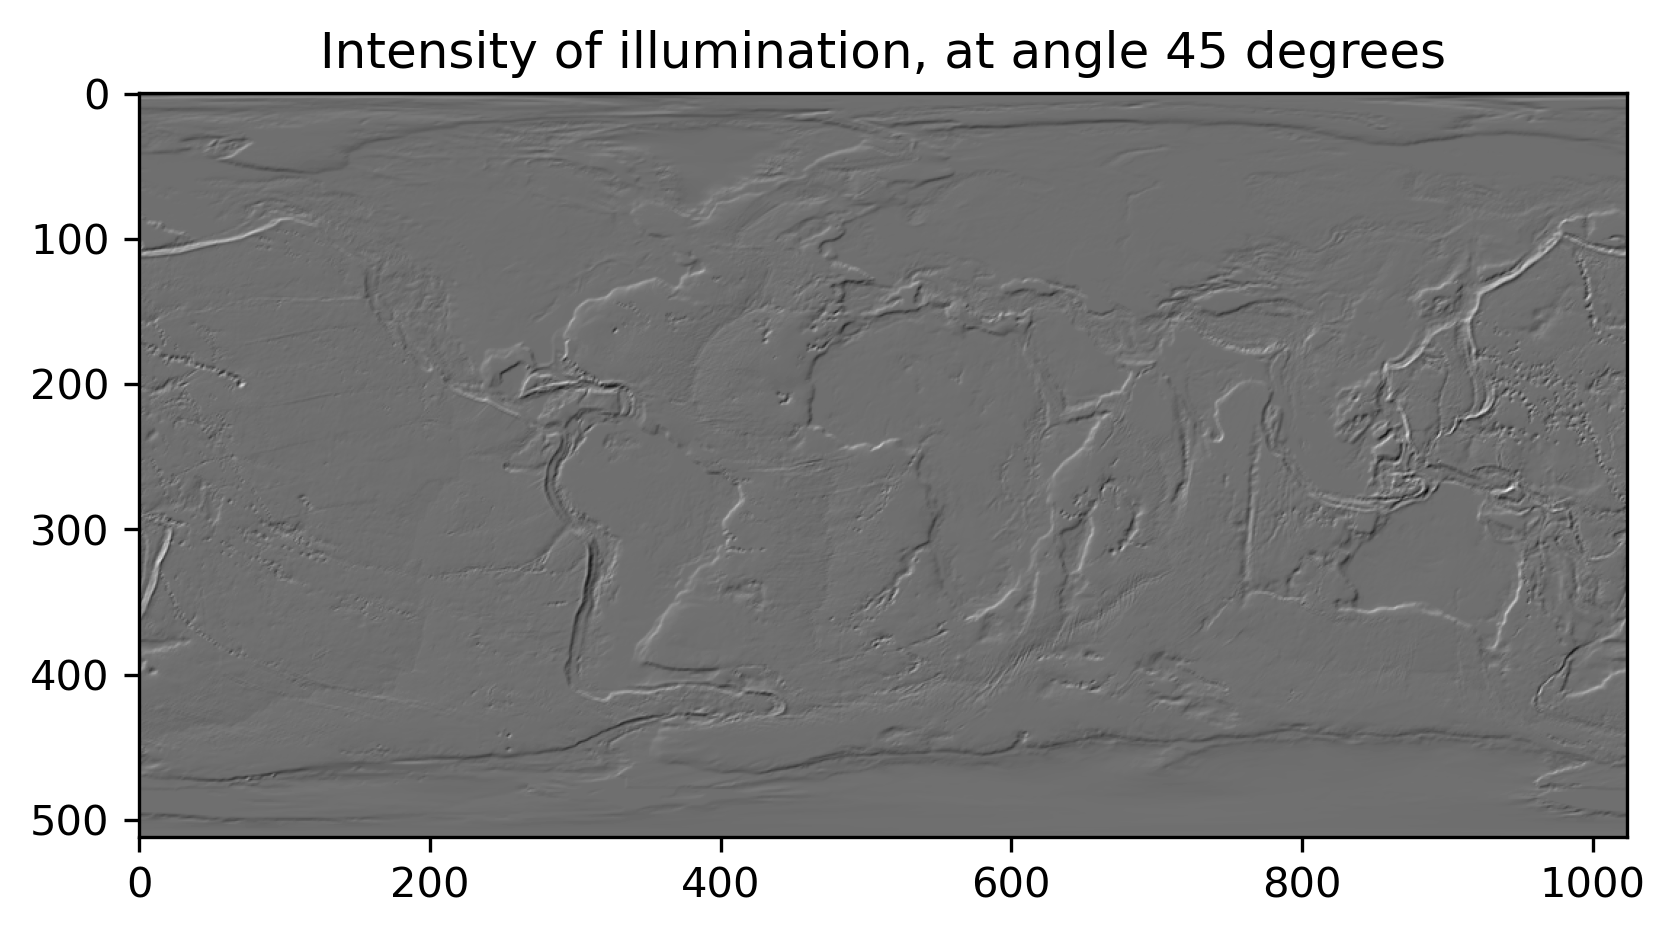

In [6]:
# exercise 5.23 - take numerical derivatives to create a "3d" map

# derivative wrt x, so axis=1
# step size h=30,000 from book, can also calculate by taking average spacing in x direction
dw_dx = np.gradient(altitude_data,30000.0, axis=1, edge_order=2) # derivative of altitude (w) wrt x
plt.figure()
plt.imshow(dw_dx)
plt.title('Derivative of altitude with respect to the x axis')
plt.show()

# derivative wrt y, so axis=0
# step size h=30,000 from book, can also calculate by taking average spacing in y direction
dw_dy = np.gradient(altitude_data,30000.0, axis=0, edge_order=2) # derivative of altitude (w) wrt y
plt.figure()
plt.imshow(dw_dy)
plt.title('Derivative of altitude with respect to the y axis')

plt.show()


# calculate intensity, based on angle of incidence

phi_deg = 45.0
phi_rad = phi_deg * (np.pi/180.0)

Intensity = ((-np.cos(phi_rad) * dw_dx) + (-np.sin(phi_rad) * dw_dy))/(np.sqrt((dw_dx)**2 + (dw_dy)**2 + 1.0))

plt.figure()
plt.imshow(Intensity)
plt.gray() # change color
plt.title('Intensity of illumination, at angle 45 degrees')
plt.show()

## Scanning Tunneling Microscope (STM)
- Python program to process an image of the surface of silicon acquired from a scanning tunnelling microscope (STM), to simulate the effect of shining a source of light onto the surface from a particular angle.

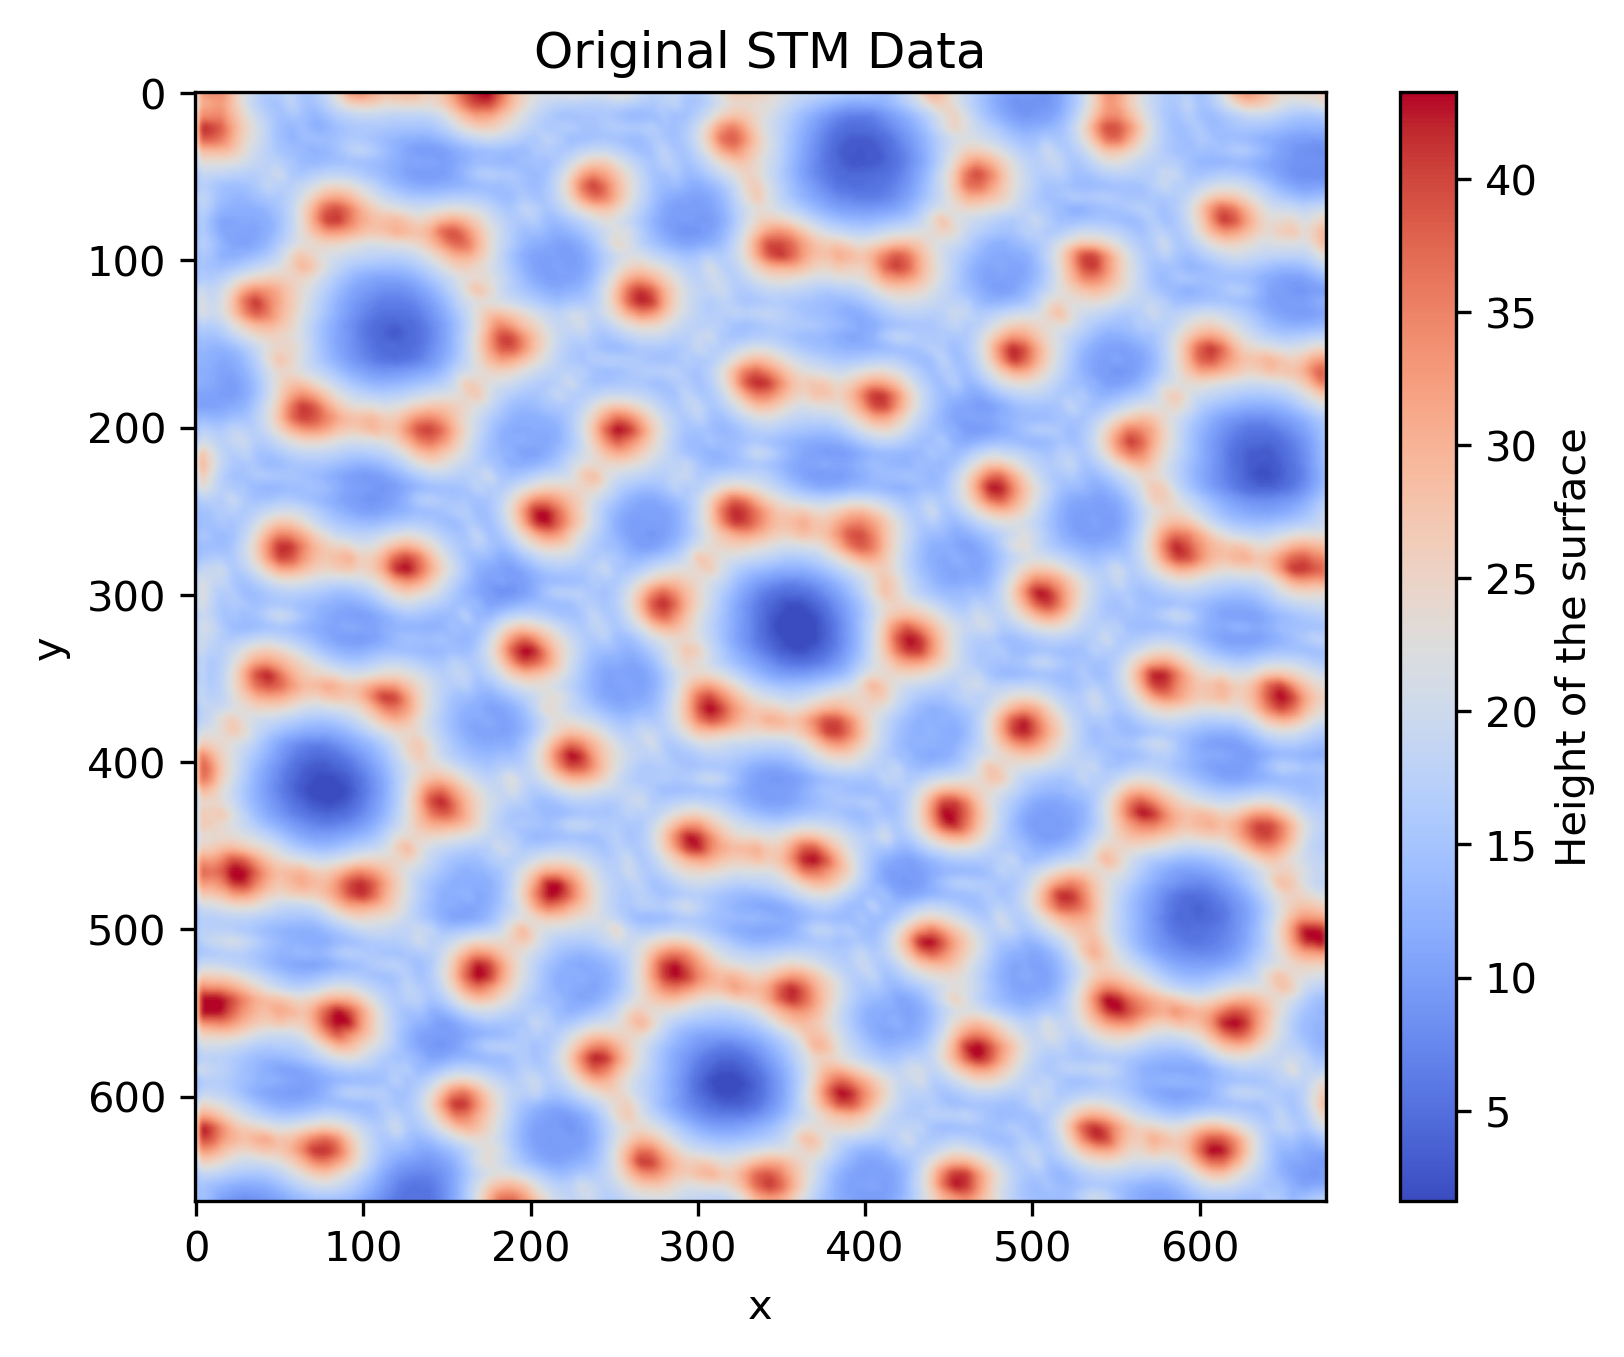

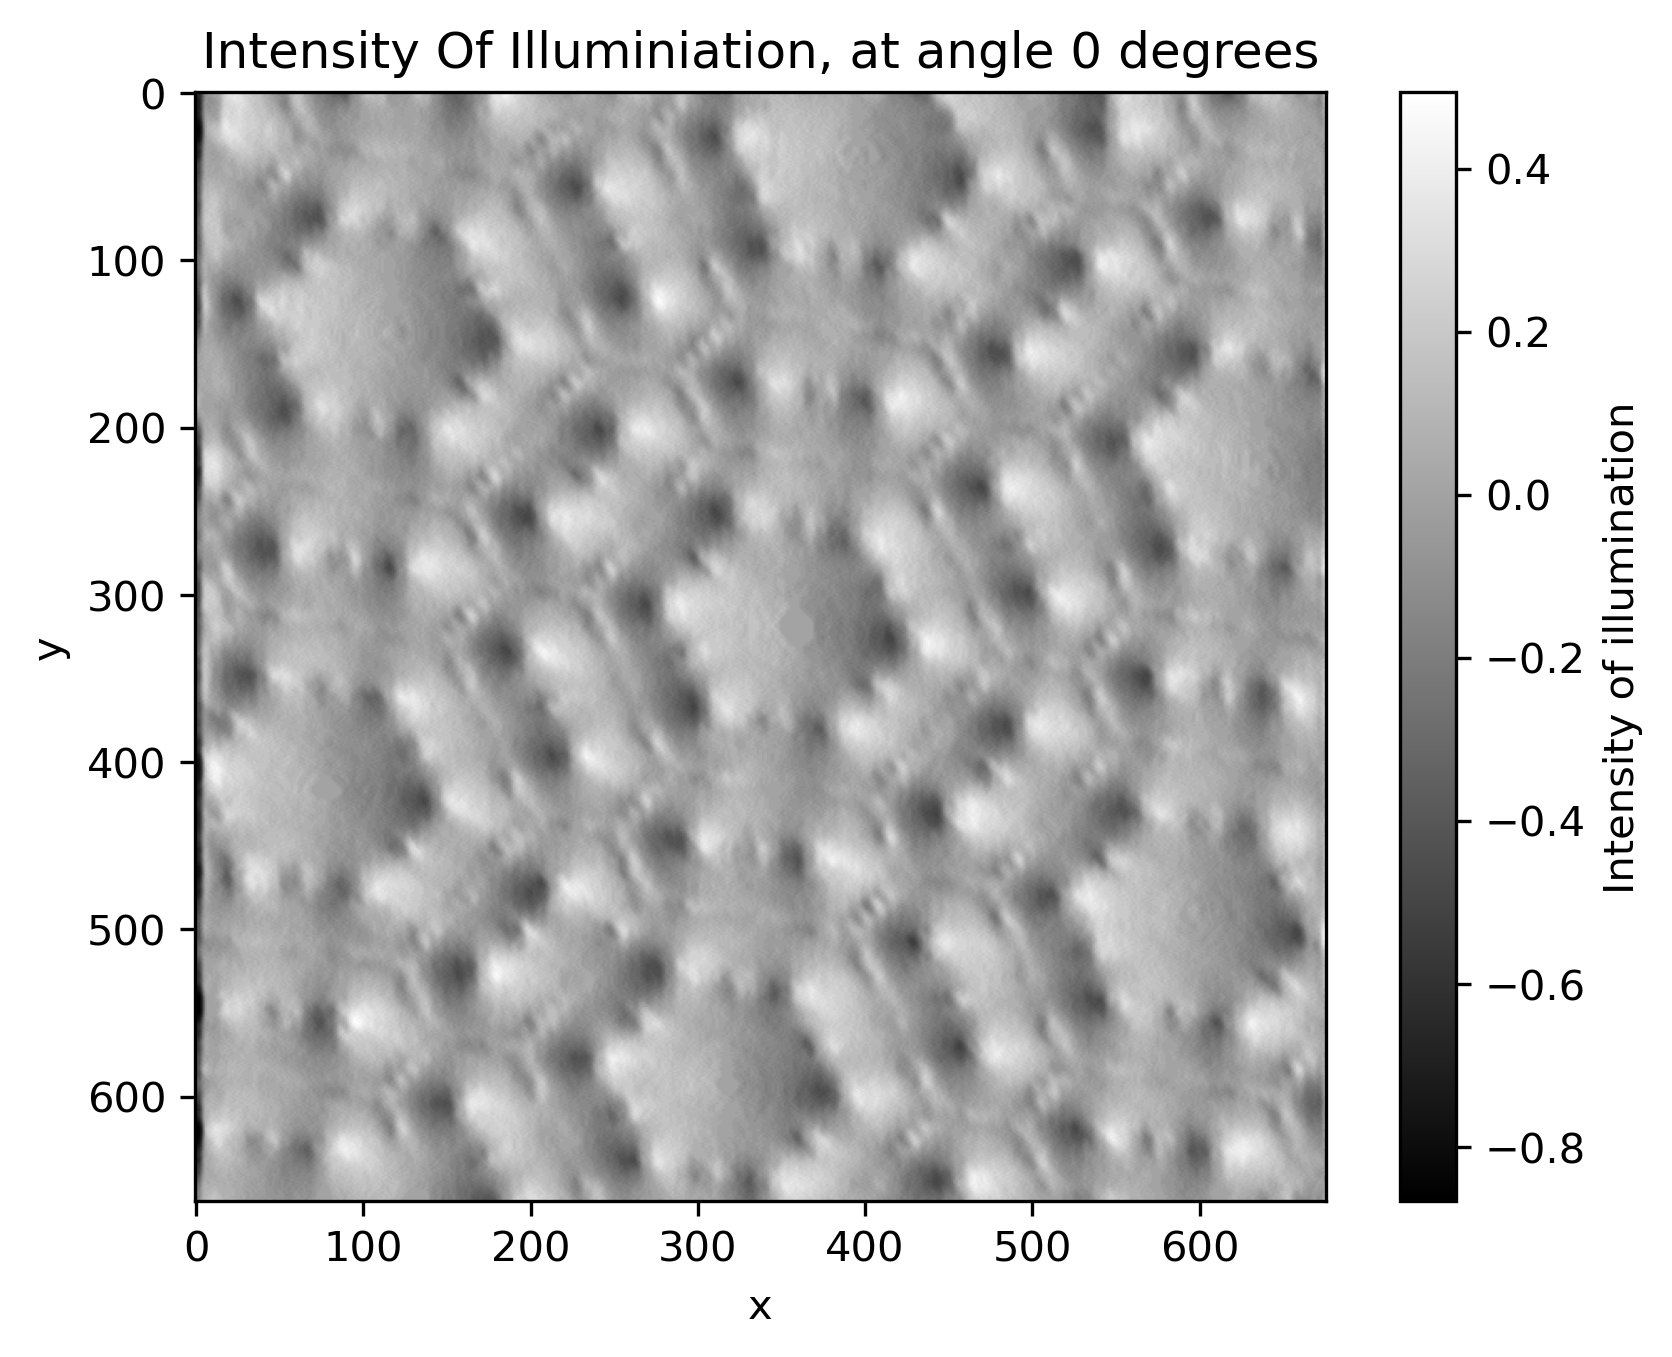

In [10]:
# exercise 5.23
# scanning tunneling microscope (stm)

from matplotlib import cm

stm_data = pd.read_csv('stm.txt', delim_whitespace=True, header=None,dtype=float)

plt.figure()
plt.imshow(stm_data, cmap=cm.coolwarm)
plt.colorbar(label='Height of the surface')
plt.ylabel(r'y', fontsize=10)
plt.xlabel(r'x',fontsize=10)
#plt.savefig('STM_OriginalData.pdf',bbox_inches = 'tight', dpi=200)
plt.title('Original STM Data')
plt.show()

# stm in 3d

# h= 2.5 (arbitrary units)
dw_dx = np.gradient(stm_data,2.5, axis=1, edge_order=2) # derivative of altitude (w) wrt x
dw_dy = np.gradient(stm_data,2.5, axis=0, edge_order=2) # derivative of altitude (w) wrt y

# calculate intensity, based on angle of incidence

phi_deg = 0.0
phi_rad = phi_deg * (np.pi/180.0)

Intensity = (((-np.cos(phi_rad) * dw_dx) + (-np.sin(phi_rad) * dw_dy))/(np.sqrt((dw_dx)**2 + (dw_dy)**2 + 1.0)))

plt.figure()
plt.imshow(Intensity)
plt.gray() # change color
plt.colorbar(label='Intensity of illumination')
plt.ylabel(r'y', fontsize=10)
plt.xlabel(r'x',fontsize=10)
#plt.savefig('STM_OriginalDataChange.pdf',bbox_inches = 'tight', dpi=200)
plt.title('Intensity Of Illuminiation, at angle 0 degrees')
plt.show()

References:

[1] Newman, M. (2013). Computational Physics.
